# 5. Methylation versus expression

*Page 5 of 9.* [previous: 4. Explainability](https://robinson-vidva.github.io/mb-methylation-xai/04_explainability.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 6. Pathways and therapy](https://robinson-vidva.github.io/mb-methylation-xai/06_pathways_and_therapy.html)

This page is what the matched expression data makes possible. A CpG can be highly discriminative
without doing anything. If promoter methylation at the model's top sites changes expression of the
gene, the explanation has biological content.

**Method.** For every gene, promoter methylation is the mean beta over its promoter probes (TSS200,
TSS1500, 5'UTR, first exon). The Spearman correlation (rho) between promoter methylation and expression
across all 763 tumours is computed for every gene with both measurements. A negative rho means that
more methylation goes with less expression, the expected direction for a promoter. The distribution
over all genes is the background. The genes under the model's top promoter CpGs are compared with it.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from pathlib import Path
TAB = Path('../results/tables')
FIG = Path('../results/figures')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)

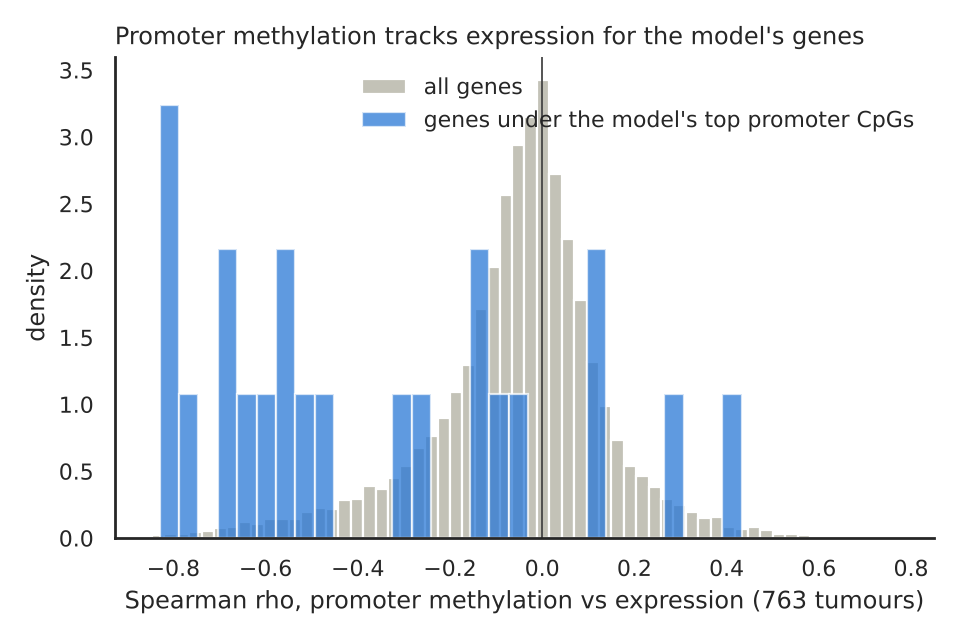

{'n_genes_tested': 15333,
 'all_genes_median_rho': -0.032803856113549586,
 'all_genes_fraction_rho_below_-0.3': 0.09606730581099589,
 'top_genes_n': 85,
 'top_genes_median_rho': -0.07452332604156746,
 'top_promoter_genes_n': 22,
 'top_promoter_genes_median_rho': -0.4857681297330989,
 'top_promoter_genes_fraction_rho_below_-0.3': 0.5909090909090909,
 'concordant_genes_per_group': {'Group3': 63,
  'Group4': 78,
  'SHH': 129,
  'WNT': 165},
 'enriched_terms_per_group': {'Group3': 46, 'SHH': 1, 'WNT': 1},
 'drivers_in_top50': 0,
 'drivers_differentially_expressed_fdr05': 20}

In [2]:
display(Image(FIG / 'methylation_vs_expression_rho.png'))
json.load(open(TAB / 'integration_summary.json'))

In [3]:
top = pd.read_csv(TAB / 'top_cpgs_with_expression_correlation.csv')
top[top['promoter_cpg']].drop_duplicates('gene').sort_values('spearman_rho')[['group', 'gene', 'cpg', 'region', 'direction', 'spearman_rho']].head(15)

,group,gene,cpg,region,direction,spearman_rho
10,WNT,VRK2,cg18998670,TSS200,hypomethylated,-0.8299
72,Group4,RBM24,cg23146346,TSS200,hypomethylated,-0.8237
79,Group4,POU2F1,cg22788908,5'UTR,hypomethylated,-0.7900
87,Group4,SLAIN1,cg21978892,5'UTR,hypomethylated,-0.7537
37,SHH,CSNK1G1,cg03840511,TSS1500,hypermethylated,-0.6946
78,Group4,LMX1A,cg23971170,TSS1500,hypomethylated,-0.6687
53,Group3,AIPL1,cg26500080,TSS200,hypomethylated,-0.6317
2,WNT,SLC20A2,cg22855020,5'UTR,hypomethylated,-0.6093
44,SHH,LRIT2,cg02790260,TSS1500,hypermethylated,-0.5600
93,Group4,PCDH9,cg27422141,5'UTR,hypermethylated,-0.5522


Across all genes the correlation is centred near zero: for most genes, promoter methylation on this
array does not track expression. For the genes under the model's top promoter CpGs it is clearly
negative, with most below -0.3. The sites the classifier relies on are, disproportionately, sites
where methylation does control expression. Examples with strong anti-correlation include VRK2 (WNT),
RBM24 and POU2F1 (Group 4) and AIPL1 (Group 3).

## Differential analysis per subgroup

The next step asks the same question subgroup by subgroup, for all genes rather than only the model's.
For each subgroup against the rest, a Mann-Whitney test is run on promoter methylation and on
expression for every gene. P-values are corrected for multiple testing with the Benjamini-Hochberg
false discovery rate (**FDR**); a gene with FDR below 0.05 is called significant. A gene is called
**concordant** when both tests are significant, the change in beta is above 0.10, the change in log2
expression is above 1 (a two-fold change), and the two changes point in opposite directions: promoter
hypomethylated with expression up, or promoter hypermethylated with expression down.

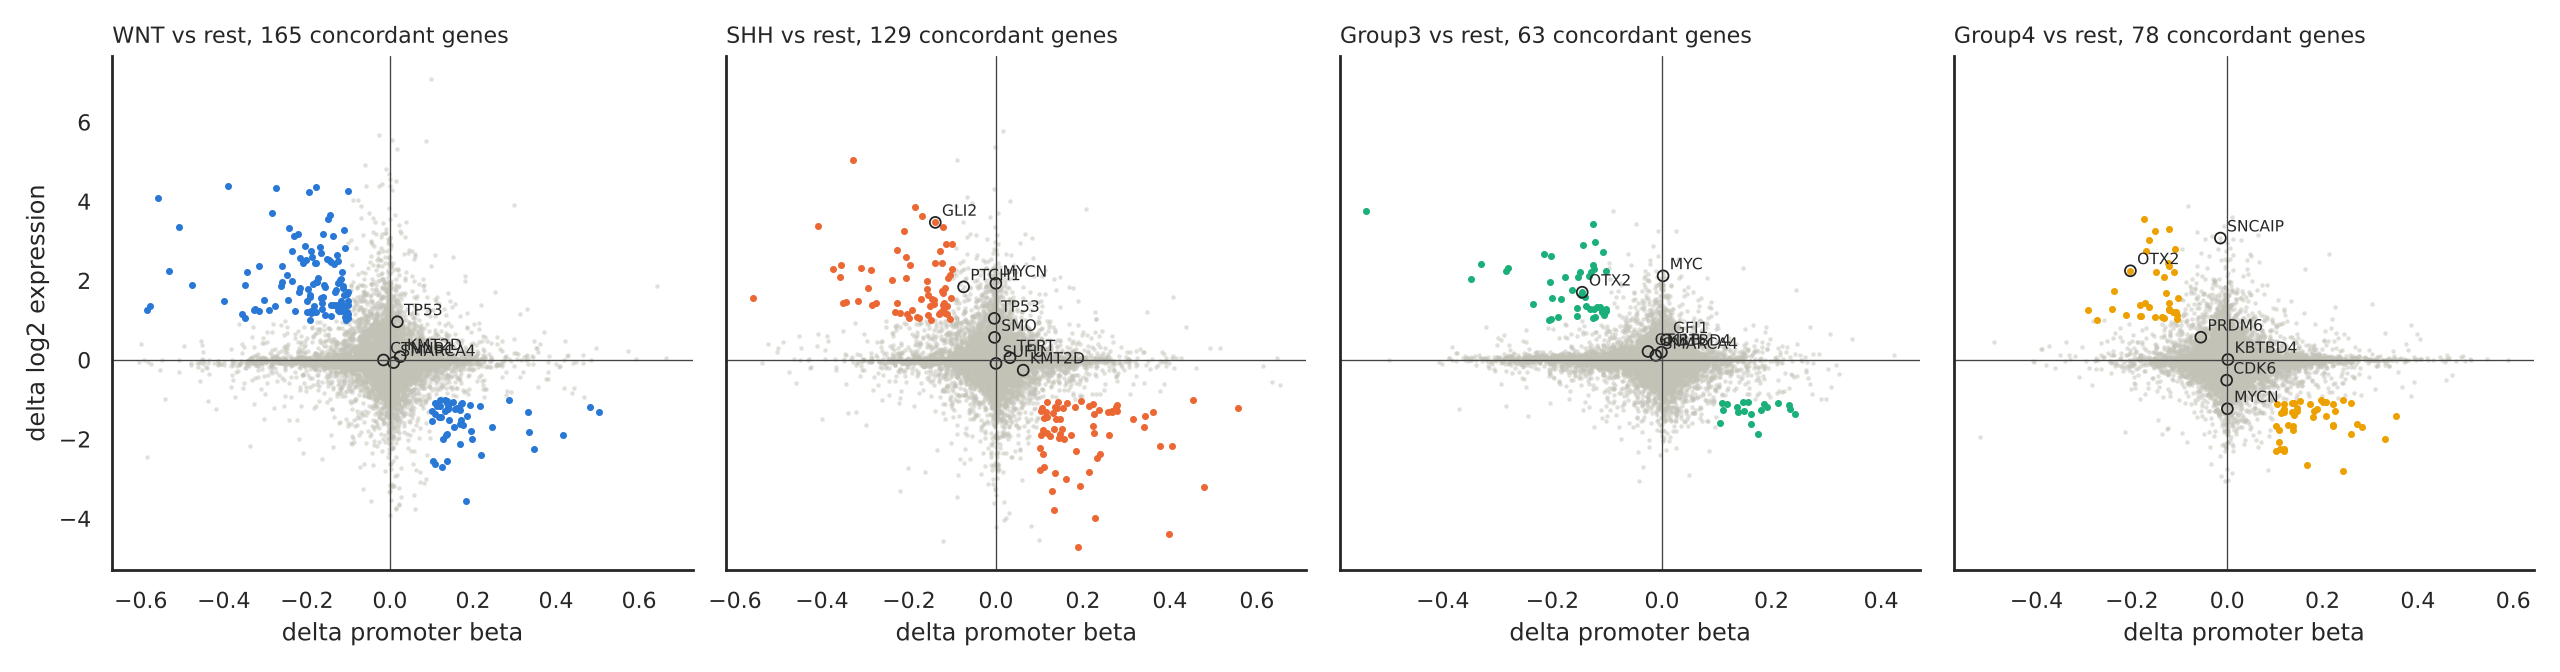

direction,"hypermethylated, expression down","hypomethylated, expression up",All
group,,,
Group3,19,44,63
Group4,44,34,78
SHH,64,65,129
WNT,51,114,165
All,178,257,435


In [4]:
display(Image(FIG / 'differential_meth_vs_expr.png'))
conc = pd.read_csv(TAB / 'concordant_genes_per_group.csv')
conc['direction'] = conc['meth_delta'].lt(0).map({True: 'hypomethylated, expression up', False: 'hypermethylated, expression down'})
pd.crosstab(conc['group'], conc['direction'], margins=True)

Each subgroup has tens to a few hundred concordant genes. Driver genes are circled in the figure.
GLI2 in SHH and OTX2 in Group 3 and Group 4 are concordant: their promoter is hypomethylated and they
are strongly expressed in their subgroup. Most other drivers are strongly over-expressed without a
promoter methylation change, which again says that drivers are switched by mutation or copy number,
not by methylation. The concordant genes are the input to the pathway and therapy page.

## The expression layer on its own

Concordant genes are a minority. Every gene and subgroup falls into one of five categories:
concordant; **expression only** (expression changed, promoter not); **methylation only** (promoter
changed, expression not); both changed in the same direction; neither. The counts show how much each
layer carries.

In [5]:
pd.read_csv(TAB / 'expression_layer_counts.csv', index_col=0)

,concordant,expression only,methylation only,"both, same direction",neither
group,,,,,
WNT,165,934,1623,51,12560
SHH,129,836,1432,43,12893
Group3,63,447,1540,14,13269
Group4,78,630,1450,19,13156


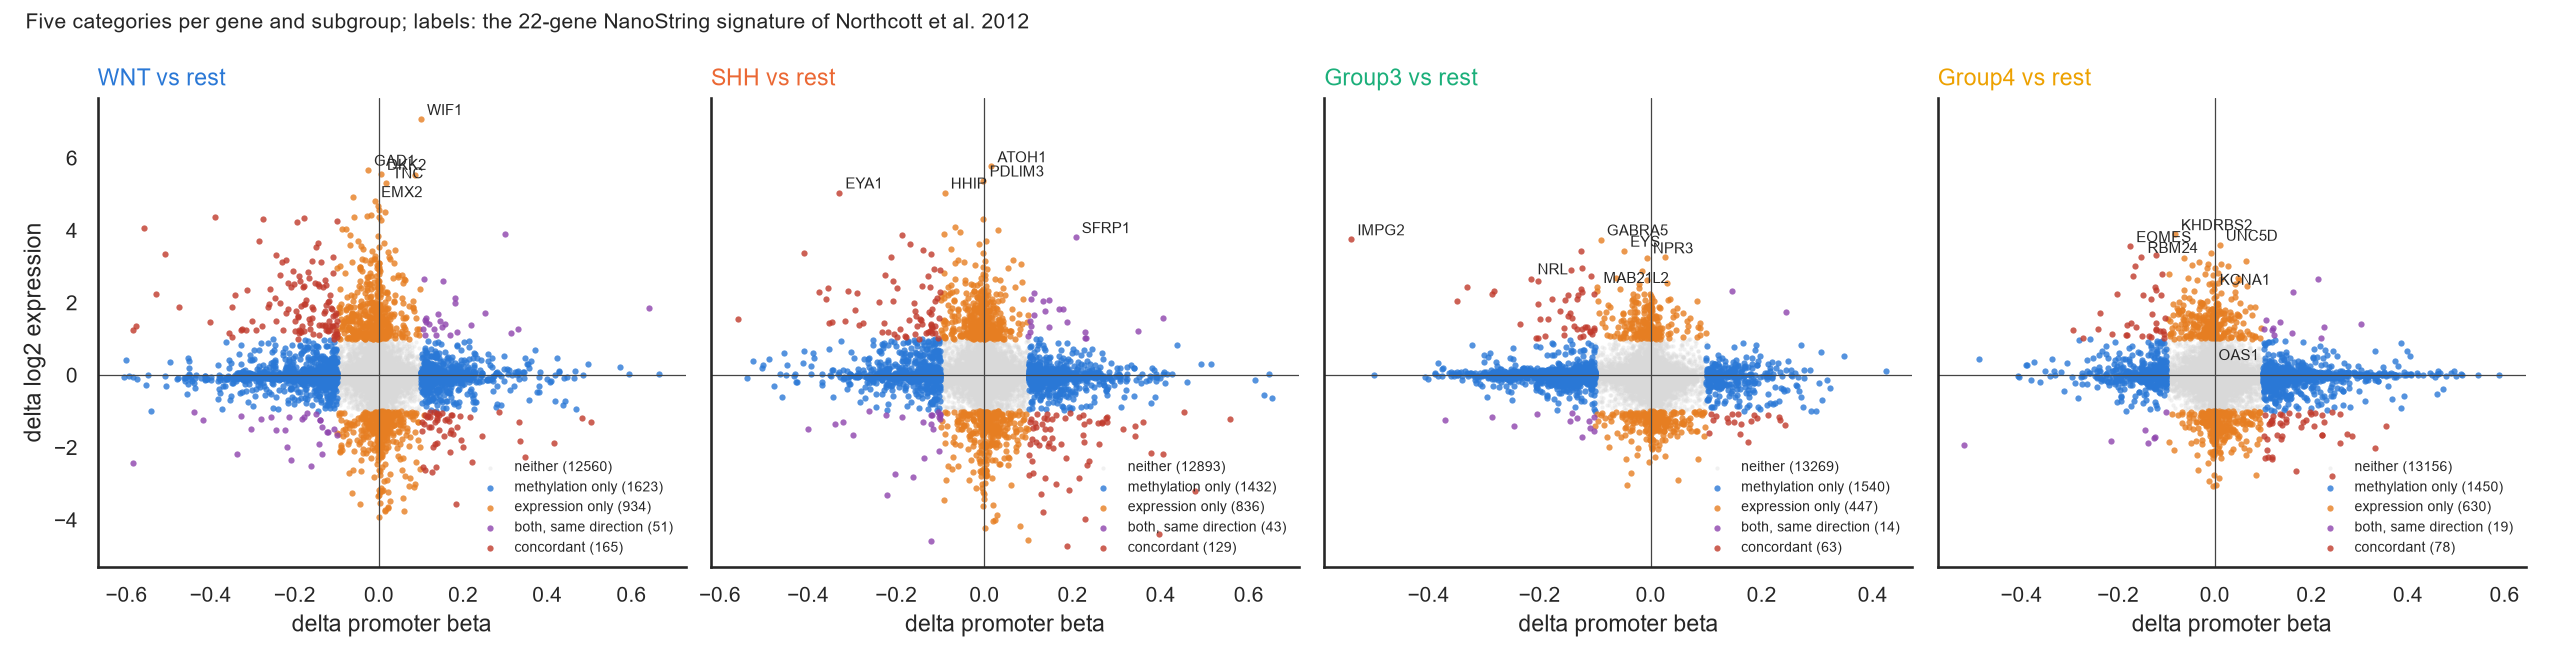

In [6]:
display(Image(FIG / 'expression_layer_scatter.png'))

**Expression-only genes outnumber concordant genes five to seven times.** They are the genes a
subgroup switches on or off without touching the promoter: through a mutated or amplified driver,
through enhancers, or through transcription factors that are themselves methylation-controlled.
The drivers sit here, as expected: MYCN, PTCH1 and TP53 up in SHH, MYC up in Group 3, SNCAIP up
in Group 4. So do the classic diagnostic markers. The 22-gene NanoString signature of Northcott et
al. 2012, the assay used to subgroup clinical FFPE samples, is labelled in the figure: 15 of its
genes are expression-only, 5 are concordant (EYA1, IMPG2, NRL, EOMES, RBM24), and only OAS1 is not
differential here. The pipeline recovers the clinical signature without being told, and the split
says which signature genes are methylation-controlled and which are not.

In [7]:
pd.read_csv(TAB / 'nanostring_signature_check.csv')

,group,gene,category,expr_delta,meth_delta,expr_fdr,meth_fdr
0,WNT,WIF1,expression only,7.0722,0.0994,0.0,0.0000
1,WNT,TNC,expression only,5.3229,0.0173,0.0,0.1245
2,WNT,GAD1,expression only,5.6701,-0.0265,0.0,0.0000
3,WNT,DKK2,expression only,5.5576,0.0044,0.0,0.0000
4,WNT,EMX2,expression only,4.8040,-0.0096,0.0,0.0000
5,SHH,PDLIM3,expression only,5.3732,-0.0021,0.0,0.3269
6,SHH,EYA1,concordant,5.0429,-0.3294,0.0,0.0000
7,SHH,HHIP,expression only,5.0397,-0.0904,0.0,0.0000
8,SHH,ATOH1,expression only,5.7672,0.0155,0.0,0.0656
9,SHH,SFRP1,"both, same direction",3.8088,0.2069,0.0,0.0000


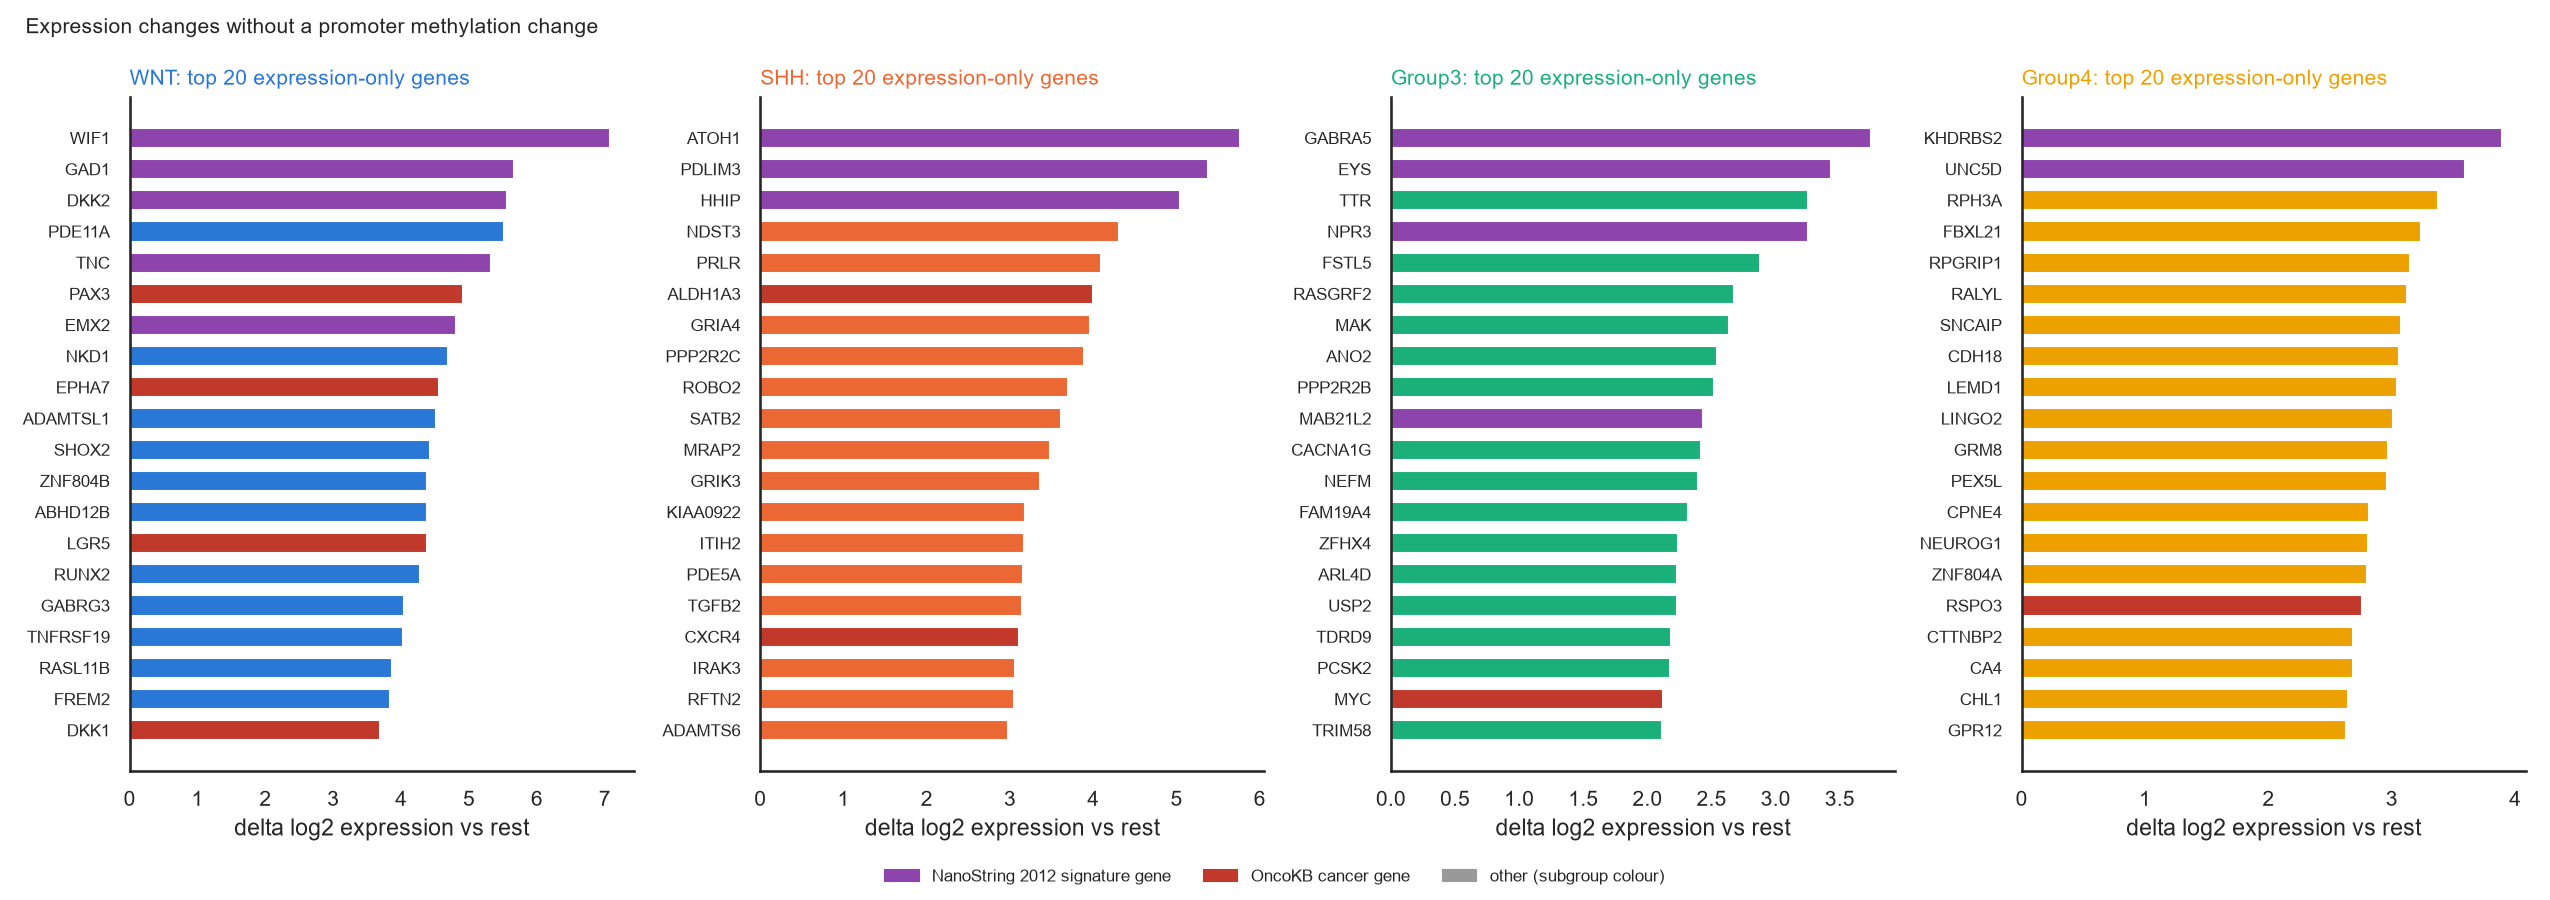

In [8]:
display(Image(FIG / 'expression_only_top_genes.png'))

**Methylation-only genes are the largest group and mostly silent.** Over a thousand genes per
subgroup change promoter methylation without a change in expression. Their enrichment is the same in
every subgroup: olfactory receptors and other "detection of chemical stimulus" genes. These genes
are not expressed in the cerebellum in any case. They lie in the large partially methylated domains
whose subgroup-specific hypomethylation Hovestadt et al. 2014 described from whole-genome bisulfite
sequencing. Their methylation reports genome organisation, not gene regulation, and a promoter change
there should not be read as a switch.

**What expression-only genes are enriched for.** Developmental and neurogenesis terms in WNT, SHH and
Group 3; synaptic signalling in Group 4, which fits the neuronal lineage proposed for Group 4.

In [9]:
enr = pd.read_csv(TAB / 'expression_layer_enrichment.csv')
enr.groupby('query').head(4)[['query', 'source', 'name', 'p_value', 'intersection_size', 'term_size']]

,query,source,name,p_value,intersection_size,term_size
0,"Group3 expression only, up",GO:BP,system development,6.260056e-09,98,3386
1,"Group3 expression only, up",GO:BP,nervous system development,1.466502e-07,72,2176
2,"Group3 expression only, up",REAC,Neuronal System,1.557063e-06,23,364
3,"Group3 expression only, up",GO:BP,multicellular organism development,4.223082e-06,101,3931
28,"Group3 methylation only, hypomethylated",GO:BP,detection of chemical stimulus involved in sensory perception,2.643948e-84,144,262
29,"Group3 methylation only, hypomethylated",GO:BP,detection of chemical stimulus,2.552318e-81,150,296
30,"Group3 methylation only, hypomethylated",GO:BP,sensory perception of chemical stimulus,1.363065e-80,152,307
31,"Group3 methylation only, hypomethylated",GO:BP,detection of chemical stimulus involved in sensory perception of smell,7.394332e-78,131,233
136,"Group4 expression only, up",GO:BP,chemical synaptic transmission,2.374998e-13,54,676
137,"Group4 expression only, up",GO:BP,anterograde trans-synaptic signaling,2.374998e-13,54,676


The division of labour is now explicit. Methylation identifies the lineage and controls a limited set
of lineage programs. Expression carries the driver output and the diagnostic markers. A classifier can
be built on either; the biology needs both.

*Page 5 of 9.* [previous: 4. Explainability](https://robinson-vidva.github.io/mb-methylation-xai/04_explainability.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 6. Pathways and therapy](https://robinson-vidva.github.io/mb-methylation-xai/06_pathways_and_therapy.html)